<img src="logo.png" alt="Vegeta" width="240">

# Svarog III — four commercial fibre lasers on Hyperion: optics, energy, thin-sheet welds, shielding

The third Svarog notebook takes **published limits** of four commercial 1070 nm fibre lasers — IPG YLS-SM (2 kW, single-mode),
Coherent FL2000C (2 kW, multimode) and FL2000CSM (2 kW, single-mode), nLIGHT WFL-3000 (3 kW, multimode) — and puts them through the
physics Svarog's own device was designed on (notebook 46, `vegeta.hyperion`): the beam (BPP ⇄ M², the fibre it implies, the
Gaussian against the multimode description through Svarog's 100/200 head), the energy balance (where the sheet is silent, a
bounded assumption and its sensitivity), the thin-sheet welds (steel and aluminium at 1, 2 and 3 mm: the keyhole threshold, the
speed, the thin-plate Rosenthal field, cooling, HAZ, distortion indicators — **a model, never a validated weld**), and the
shielding assessment (the raw collimated beam and a specular reflection at 5–100 m against polycarbonate, aluminium and wood:
the MPE, the transmitted and reflected shares, a non-destructive bound on the barrier's heating, the fire risk of wood, and
a verdict **PASS / FAIL / INCOMPLETE** in which PASS needs certified protection evidence this notebook cannot produce).

The specs are `designs/data/svarog_commercial_specs.json` — verbatim, unknowns preserved; the code `designs/svarog_commercial.py`
(`sc`) and its drawings; every assumption is a named `sc.ASSUMPTIONS` entry with a range. Yanus takes notebook 46's report
(the Svarog devices as reference rows) and book fenix's F4 `shield-steady` runs (FEniCSx steady states of the same panels,
made only by `wf run F4 --variant <laser>`) as optional inputs: without them the tables say NOT RUN and the closed forms stand.
Nothing here computes a burn-through time: the barriers' question is whether they could ever be shown safe, not how long they last.
No internet, no prices, no robot: the physics of the sheets. Runtime: under a minute.

In [1]:
DEBUG = False
from vegeta import mock
DEBUG = mock.setup(DEBUG)

In [2]:
import json, math, os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, "designs")
from vegeta import hyperion as hy
from vegeta.hyperion import thermal as th, welding as wd
import svarog_industrial as si
import svarog_commercial as sc, svarog_commercial_drawings as scd

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
DATA = Path("designs/data")
OUT = Path("output/47_svarog_iii"); OUT.mkdir(parents=True, exist_ok=True)
from vegeta import yanus
GATE = yanus.enter("47_svarog_iii", debug=DEBUG)      # the door keeper: needs vegeta.hyperion; takes the specs, 46's report and the F4 runs (all optional); gives the record
R46_KEY = "46_svarog:notebooks/designs/data/reports/46_svarog.json"
_row = next(r for r in GATE.rows if r.key == R46_KEY)
R46 = json.loads(Path(GATE.inputs[R46_KEY]).read_text()) if _row.usable else None
print("notebook 46's report:", "taken (the Svarog 1 kW and 2 kW as reference rows)" if R46 else f"NOT RUN — {_row.status}; {_row.fix or 'run notebook 46_svarog'}: the reference rows are left out")
def fenix(laser):
    return GATE.inputs.get(f"fenix/shield-steady@{laser}"), GATE.selections.get(f"fenix/shield-steady@{laser}")

notebook 46's report: taken (the Svarog 1 kW and 2 kW as reference rows)


## 1. The four lasers, as published

The sheet's numbers are **limits** — an M² "< 1.1", a stability "±1 %", an electrical "maximum" — not operating values; what it
does not say stays *Unknown* and is never filled in. Two checks before any physics: does the beam-quality column agree with the
mode column (M² ⇄ BPP, `BPP = M² λ/π`), and does the published cooling capacity hold the waste heat the electrical maximum implies.

In [3]:
SPECS = pd.DataFrame({s.name: {k: ("Unknown" if v is None else v) for k, v in s.to_dict().items() if k not in ("key", "maker", "model", "source")} for s in sc.LASERS.values()}).T
display(SPECS)
print("source:", next(iter(sc.LASERS.values())).source)
OPT = {k: sc.optics(s) for k, s in sc.LASERS.items()}
ENERGY = {k: sc.energy_balance(s) for k, s in sc.LASERS.items()}
CHECKS = pd.DataFrame({sc.LASERS[k].name: {"M² ⇄ BPP consistent": OPT[k]["m2_bpp_consistent"], "mode matches M²": OPT[k]["mode_matches_m2"], "beam-quality basis": OPT[k]["basis"],
                                            "cooling vs electrical": ENERGY[k]["cooling_note"]} for k in sc.LASERS}).T
display(CHECKS)

,power_W,wavelength,mode,m2_max,bpp_max_mm_mrad,stability_pct,modulation_kHz,connected_kVA,electrical_max_kW,cooling_kW,notes
IPG YLS-SM,2000.0,0.000001,single,1.1,Unknown,Unknown,10,Unknown,Unknown,Unknown,M² given as '<1.1' (a limit); every electrical number unknown
Coherent FL2000C,2000.0,0.000001,multi,Unknown,2.5,1.0,10,6.4,6.2,4.4,stability '±1 %'
Coherent FL2000CSM,2000.0,0.000001,single,Unknown,0.4,1.0,10,6.4,6.2,4.4,stability '±1 %'
nLIGHT WFL-3000,3000.0,0.000001,multi,Unknown,2.0,1.0,20,Unknown,Unknown,Unknown,stability '≤1 %'; every electrical number unknown


source: user-supplied table of published limits, 2026-10-17; treated as limits, not operating values; null = Unknown (preserved, never filled in)


,M² ⇄ BPP consistent,mode matches M²,beam-quality basis,cooling vs electrical
IPG YLS-SM,True,True,M² published; BPP = M² λ/π,no published cooling capacity: the waste heat's bound sizes the chiller
Coherent FL2000C,True,True,BPP published; M² = π BPP/λ,published capacity 4400 W against the waste heat's bound 4200 W: consistent
Coherent FL2000CSM,True,True,BPP published; M² = π BPP/λ,published capacity 4400 W against the waste heat's bound 4200 W: consistent
nLIGHT WFL-3000,True,True,BPP published; M² = π BPP/λ,no published cooling capacity: the waste heat's bound sizes the chiller


## 2. Optics

From the beam quality to the beam at the work and the beam that escapes. The BPP decides the delivery fibre (the smallest listed
fibre whose r·NA holds it — an étendue match, not a vendor's part) and, through Svarog's 100/200 head, the spot: for a multimode
beam the *core is imaged* (spot = r_core × 2, cone = NA/2: geometric optics, the Gaussian is only an envelope); for M² ≲ 1.5 the
*embedded Gaussian* is the beam (w₀ = M² λ f/πW, the Rayleigh range follows). The collimated beam's radius W = NA·f_c and its
growth per metre (the larger of the geometric r_core/f_c and the Gaussian M²λ/πW) are the numbers the shielding needs. The optical
efficiency to the work is the process fibre's loss and the lenses' absorption, as ranges; the stability band is the sheet's.

,IPG YLS-SM,Coherent FL2000C,Coherent FL2000CSM,nLIGHT WFL-3000
mode (published),single,multi,single,multi
M²,1.1,7.34017,1.174427,5.872136
BPP [mm·mrad],0.374651,2.5,0.4,2.0
basis,M² published; BPP = M² λ/π,BPP published; M² = π BPP/λ,BPP published; M² = π BPP/λ,BPP published; M² = π BPP/λ
M²/BPP consistent,True,True,True,True
mode matches M²,True,True,True,True
fibre class,14/125 feeding fibre,50/125 process fibre,14/125 feeding fibre,50/125 process fibre
regime,Gaussian (embedded M² is the beam),multimode (the core is imaged; the Gaussian is only an envelope),Gaussian (embedded M² is the beam),multimode (the core is imaged; the Gaussian is only an envelope)
spot radius [µm],9.366268,50.0,10.0,50.0
"spot, core imaged [µm]",14.0,50.0,14.0,50.0


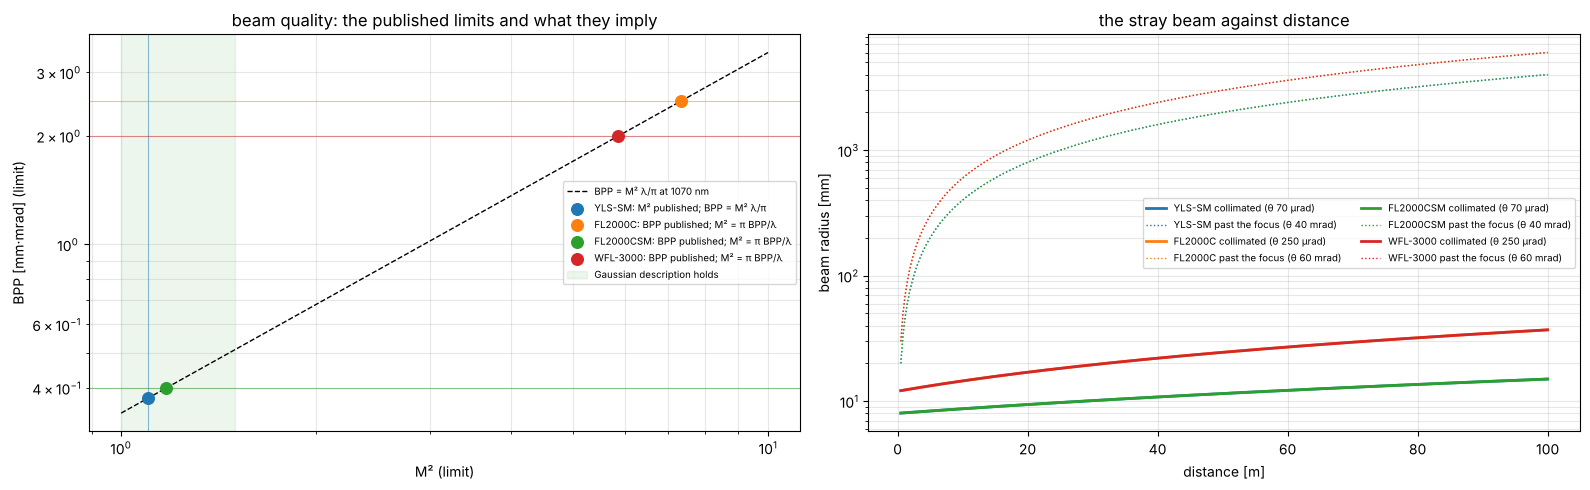

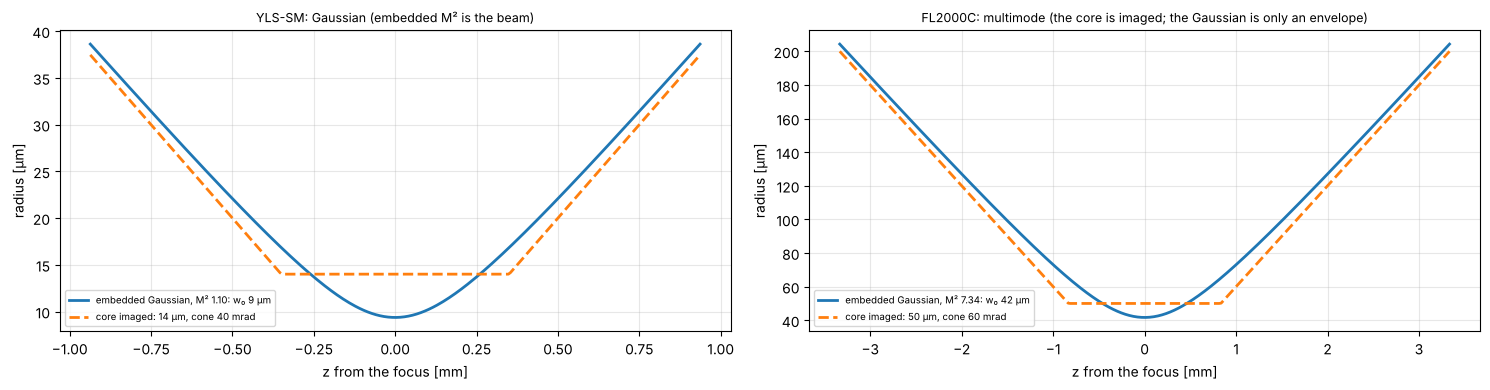

the single-mode lasers through the same head: a 10 µm spot at 600 MW/cm² — a cutting beam; welding sheets with it asks for a longer focal length or a wobble (not analysed here)


In [4]:
OT = sc.optics_table()
display(OT.T)
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
scd.beam_quality_view(OPT, ax=axs[0]); scd.propagation_view(OPT, ax=axs[1])
plt.tight_layout(); plt.savefig(OUT / "beam_quality.png", dpi=110); plt.show()
fig, axs = plt.subplots(1, 2, figsize=(15, 4))
scd.gaussian_vs_multimode_view(OPT["YLS-SM"], ax=axs[0]); scd.gaussian_vs_multimode_view(OPT["FL2000C"], ax=axs[1])
plt.tight_layout(); plt.savefig(OUT / "propagation.png", dpi=110); plt.show()
print("the single-mode lasers through the same head: a 10 µm spot at 600 MW/cm² — a cutting beam; welding sheets with it asks for a longer focal length or a wobble (not analysed here)")

## 3. Electrical and thermal

Electrical in = P / (η_diode η_driver η_optical) + auxiliaries; waste heat = electrical − optical; the chiller takes heat/COP more;
connected power = total / power factor. Where the sheet publishes the electrical maximum (the Coherent pair: 6.2 kW) it caps the
estimate and the published 4.4 kW cooling capacity is checked against the 4.2 kW of waste heat that maximum implies (consistent:
a capacity above the heat). For the YLS-SM and the WFL-3000 nothing electrical is published: the assumptions' ranges give the
interval, and the sensitivity table says which assumption moves it most (the diode efficiency).

,IPG YLS-SM,Coherent FL2000C,Coherent FL2000CSM,nLIGHT WFL-3000
optical out [kW],2.0,2.0,2.0,3.0
electrical in [kW],6.23 (4.80–7.72),6.20 (4.80–6.20),6.20 (4.80–6.20),9.19 (7.10–11.32)
wall-plug,0.32 (0.26–0.42),0.32 (0.32–0.42),0.32 (0.32–0.42),0.33 (0.26–0.42)
waste heat [kW],4.23 (2.80–5.72),4.20 (2.80–4.20),4.20 (2.80–4.20),6.19 (4.10–8.32)
published cooling [kW],None,4.4,4.4,None
cooling check,no published cooling capacity: the waste heat's bound sizes the chiller,published capacity 4400 W against the waste heat's bound 4200 W: consistent,published capacity 4400 W against the waste heat's bound 4200 W: consistent,no published cooling capacity: the waste heat's bound sizes the chiller
chiller electrical [kW],1.41 (0.80–2.29),1.40 (0.80–1.68),1.40 (0.80–1.68),2.06 (1.17–3.33)
total with chiller [kW],7.63 (5.60–10.00),7.60 (5.60–7.88),7.60 (5.60–7.88),11.25 (8.27–14.65)
"connected, laser + chiller [kVA]",8.04 (5.71–11.11),8.00 (5.71–8.76),8.00 (5.71–8.76),11.84 (8.44–16.28)
published connected [kVA],None,6.4,6.4,None


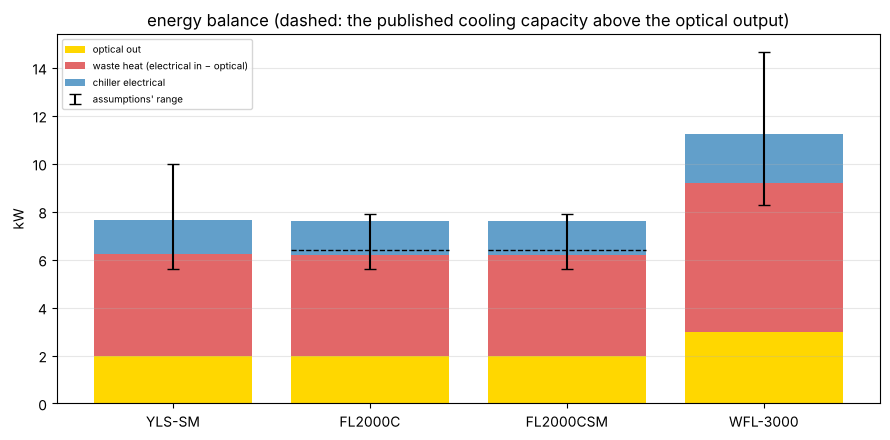

assumption   end   value  electrical_W  wall_plug  total_with_chiller_W
YLS-SM   0    diode_eff   low    0.45      6884.362      0.291              8512.483
         1    diode_eff  high    0.55      5687.205      0.352              6916.274
         2   driver_eff   low    0.88      6360.606      0.314              7814.141
         3   driver_eff  high    0.93      6034.767      0.331              7379.689
         4  optical_eff   low    0.70      6649.206      0.301              8198.942
         5  optical_eff  high    0.85      5528.758      0.362              6705.011
         6        aux_W   low  200.00      6125.926      0.326              7501.235
         7        aux_W  high  500.00      6425.926      0.311              7901.235
         8  cooling_COP   low    2.50      6225.926      0.321              7916.296
         9  cooling_COP  high    3.50      6225.926      0.321              7433.333
WFL-3000 0    diode_eff   low    0.45     10176.543      0.295             12568.724
         1    diode_eff  high    0.55      8380.808      0.358             10174.411
         2   driver_eff   low    0.88      9390.909      0.319             11521.212
         3   driver_eff  high    0.93      8902.151      0.337             10869.534
         4  optical_eff   low    0.70      9823.810      0.305             12098.413
         5  optical_eff  high    0.85      8143.137      0.368              9857.516
         6        aux_W   low  200.00      9088.889      0.330             11118.519
         7        aux_W  high  500.00      9388.889      0.320             11518.519
         8  cooling_COP   low    2.50      9188.889      0.326             11664.444
         9  cooling_COP  high    3.50      9188.889      0.326             10957.143

assumptions:


,nominal,low,high,unit,basis
diode_eff,0.5,0.45,0.55,-,976 nm pump diodes' electrical-to-optical efficiency (class of today's modules)
driver_eff,0.9,0.88,0.93,-,the diode drivers' (switch-mode) efficiency
optical_eff,0.75,0.7,0.85,-,pump-to-signal conversion of a Yb MOPA including combiners and splices (Svarog's 1 kW ...
aux_W,300.0,200.0,500.0,W,"controls, fans, pumps and the diode's thermo-electric coolers where fitted"
cooling_COP,3.0,2.5,3.5,-,"a compressor chiller's coefficient of performance at 20 °C water, 35 °C air"
power_factor,0.95,0.9,0.98,-,a PFC-corrected three-phase supply
delivery_loss_dB,0.3,0.2,0.5,dB,the process fibre and its connectors (Svarog: 0.3 dB on 20 m)
lens_absorption,0.002,0.001,0.003,-,each of the head's two lenses (coated fused silica at 1 µm)
abs_keyhole_steel,0.7,0.5,0.8,-,keyhole absorptivity of mild steel at 1 µm (multiple reflections; svarog_industrial.WE...
abs_keyhole_al,0.5,0.35,0.6,-,keyhole absorptivity of aluminium at 1 µm


In [5]:
ET = sc.energy_table(); display(ET.T)
scd.energy_view(ENERGY); plt.tight_layout(); plt.savefig(OUT / "energy.png", dpi=110); plt.show()
SENS = pd.concat({k: sc.energy_sensitivity(sc.LASERS[k]) for k in ("YLS-SM", "WFL-3000")})
display(SENS.round(3))
print("assumptions:"); display(pd.DataFrame({k: {"nominal": a.nominal, "low": a.low, "high": a.high, "unit": a.unit, "basis": a.basis} for k, a in sc.ASSUMPTIONS.items()}).T)

## 4. Welding reference cases — steel and aluminium sheets, 1, 2, 3 mm

Six sheets per laser (`sc.SHEET_MATERIALS`: an S235JR-class mild steel and an EN AW-5754-class aluminium, uncoated, butt
configuration, no gap), each laser at its delivered power and its own spot: the keyhole threshold (the surface boiling under the
spot: `wd.keyhole_threshold`), the speed that puts 1.2 × the thickness of depth from the energy balance (`wd.speed_for_penetration`,
with the keyhole absorptivity and the melting efficiency as ranges → the speed's interval), the heat input, and the **thin-plate
Rosenthal field** at that speed (`wd.rosenthal_thin_plate`, the line source of EN 1011-2's two-dimensional regime): the pool's
width and length, the solidification time of a point on the centreline, the thermal gradient at the fusion boundary, the cooling —
t8/5 for steel (`wd.cooling_time_t85`), the cooling rate at the melt for aluminium (`wd.cooling_rate_at`) — the HAZ (`wd.haz_width`:
Ac1 for steel, over-ageing for aluminium) and a distortion index (angular distortion ∝ absorbed heat input / t², Watanabe–Satoh,
in kelvin as a mean rise of the sheet). Flags: humping above ~6 m/min, a marginal keyhole below 3 × the threshold, and each alloy's
defect list. **None of it is validated**: no penetration, no strength is claimed — the trial matrix of svarog_todo M.3 decides.
Notebook 46's Svarog devices appear as reference rows when its report is at hand.

24 cases in 17 s


material  t [mm]  spot [µm]  P/P_keyhole  v [m/min] v low–high [m/min]  feasible (model)  heat input [J/mm]  pool width [mm]  pool length [mm]  solidification [ms]  t8/5 [s]  cooling rate at melt [K/s]  \
YLS-SM    0     S235JR-class mild steel     1.0      9.366      264.795     47.892      (17.91, 60.0)              True              2.329            0.107             0.400                0.481     0.005                 1405584.123   
          1     S235JR-class mild steel     2.0      9.366      264.795     15.994      (5.52, 26.67)              True              6.974            0.146             0.308                1.038     0.016                  627057.116   
          2     S235JR-class mild steel     3.0      9.366      264.795      8.075      (2.67, 13.79)              True             13.814            0.172             0.273                1.705     0.031                  359606.989   
          3  EN AW-5754-class aluminium     1.0      9.366       19.393     49.932      (15.58, 60.0)              True              2.234            0.260             0.419                0.424     0.001                  530227.462   
          4  EN AW-5754-class aluminium     2.0      9.366       19.393     14.237      (4.22, 27.78)              True              7.835            0.292             0.337                0.998     0.002                  172419.932   
          5  EN AW-5754-class aluminium     3.0      9.366       19.393      6.651       (1.93, 13.2)              True             16.770            0.244             0.255                1.412     0.005                   84671.934   
FL2000C   0     S235JR-class mild steel     1.0     50.000       49.603      8.971      (3.36, 14.35)              True             12.433            0.569             2.136               13.719     0.086                   49323.062   
          1     S235JR-class mild steel     2.0     50.000       49.603      2.996        (1.03, 5.0)              True             37.230            0.781             1.642               29.587     0.193                   22003.932   
          2     S235JR-class mild steel     3.0     50.000       49.603      1.513        (0.5, 2.58)              True             73.743            0.916             1.458               48.589     0.337                   12618.895   
          3  EN AW-5754-class aluminium     1.0     50.000        3.633      9.354      (2.92, 17.57)              True             11.925            1.390             2.235               12.081     0.015                   18606.102   
          4  EN AW-5754-class aluminium     2.0     50.000        3.633      2.667        (0.79, 5.2)              True             41.824            1.560             1.799               28.448     0.046                    6050.352   
          5  EN AW-5754-class aluminium     3.0     50.000        3.633      1.246       (0.36, 2.47)              True             89.525            1.300             1.360               40.251     0.093                    2971.205   
FL2000CSM 0     S235JR-class mild steel     1.0     10.000      248.014     44.857      (16.78, 60.0)              True              2.487            0.114             0.427                0.549     0.006                 1233076.555   
          1     S235JR-class mild steel     2.0     10.000      248.014     14.980      (5.17, 24.98)              True              7.446            0.156             0.328                1.183     0.017                  550098.295   
          2     S235JR-class mild steel     3.0     10.000      248.014      7.563       (2.5, 12.91)              True             14.749            0.183             0.292                1.944     0.033                  315472.365   
          3  EN AW-5754-class aluminium     1.0     10.000       18.164     46.768       (14.6, 60.0)              True              2.385            0.278             0.447                0.483     0.001                  465152.560   
          4  EN AW-

reference: notebook 46's Svarog devices at the same rule (1.2 × depth)


,device,material,t [mm],v margin [m/min],feasible (model)
0,Svarog 1kW,mild steel,1.0,3.02,True
1,Svarog 1kW,mild steel,2.0,0.92,True
2,Svarog 1kW,mild steel,3.0,0.44,True
3,Svarog 1kW,aluminium,1.0,2.69,True
4,Svarog 1kW,aluminium,2.0,0.73,True
5,Svarog 1kW,aluminium,3.0,0.33,True
6,Svarog 2kW,mild steel,1.0,4.31,True
7,Svarog 2kW,mild steel,2.0,1.43,True
8,Svarog 2kW,mild steel,3.0,0.72,True
9,Svarog 2kW,aluminium,1.0,4.46,True


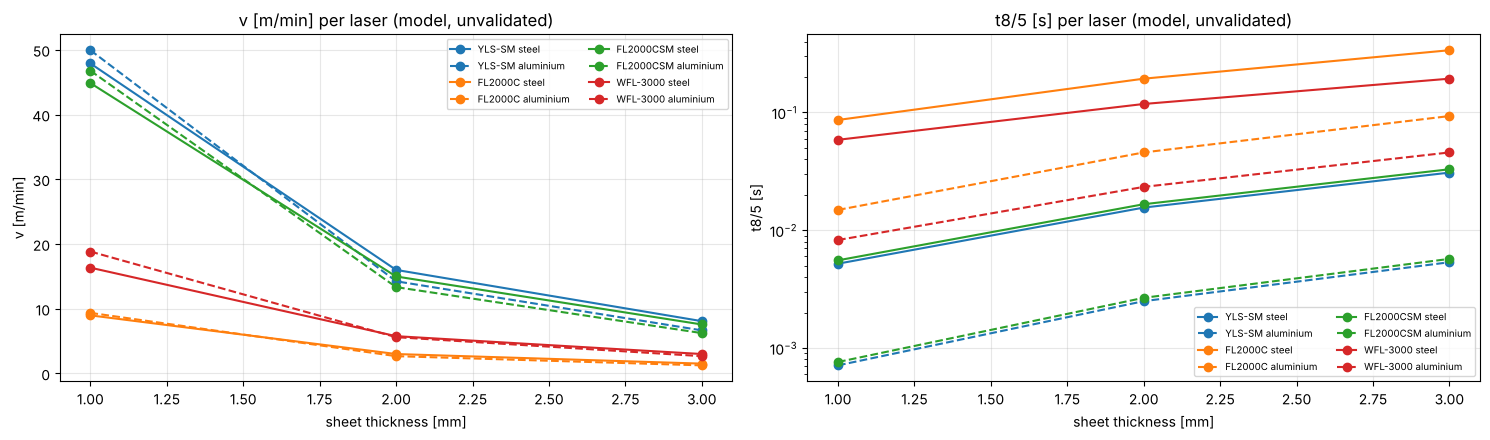

In [6]:
t0 = time.time()
WELDS = {k: sc.welding_cases(sc.LASERS[k], OPT[k]) for k in sc.LASERS}
print(f"{sum(len(v) for v in WELDS.values())} cases in {time.time() - t0:.0f} s")
WT = {k: sc.welding_table(v) for k, v in WELDS.items()}
display(pd.concat(WT).round(3).drop(columns=["laser"]))
if R46:
    rows = []
    for v in ("1kW", "2kW"):
        for mat in ("mild steel", "aluminium"):
            for w in R46["industrial"][v]["welds"][mat]["window"]:
                if w["thickness"] in sc.THICKNESSES:
                    rows.append({"device": f"Svarog {v}", "material": mat, "t [mm]": w["thickness"] * 1e3, "v margin [m/min]": (w["v_with_margin"] or float('nan')) * 60, "feasible (model)": w["feasible"]})
    print("reference: notebook 46's Svarog devices at the same rule (1.2 × depth)"); display(pd.DataFrame(rows).round(2))
else:
    print("reference rows: NOT RUN (notebook 46's report missing)")
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
scd.welding_comparison_view(WT, "v [m/min]", ax=axs[0]); scd.welding_comparison_view(WT, "t8/5 [s]", ax=axs[1]); axs[1].set_yscale("log")
plt.tight_layout(); plt.savefig(OUT / "welding.png", dpi=110); plt.show()

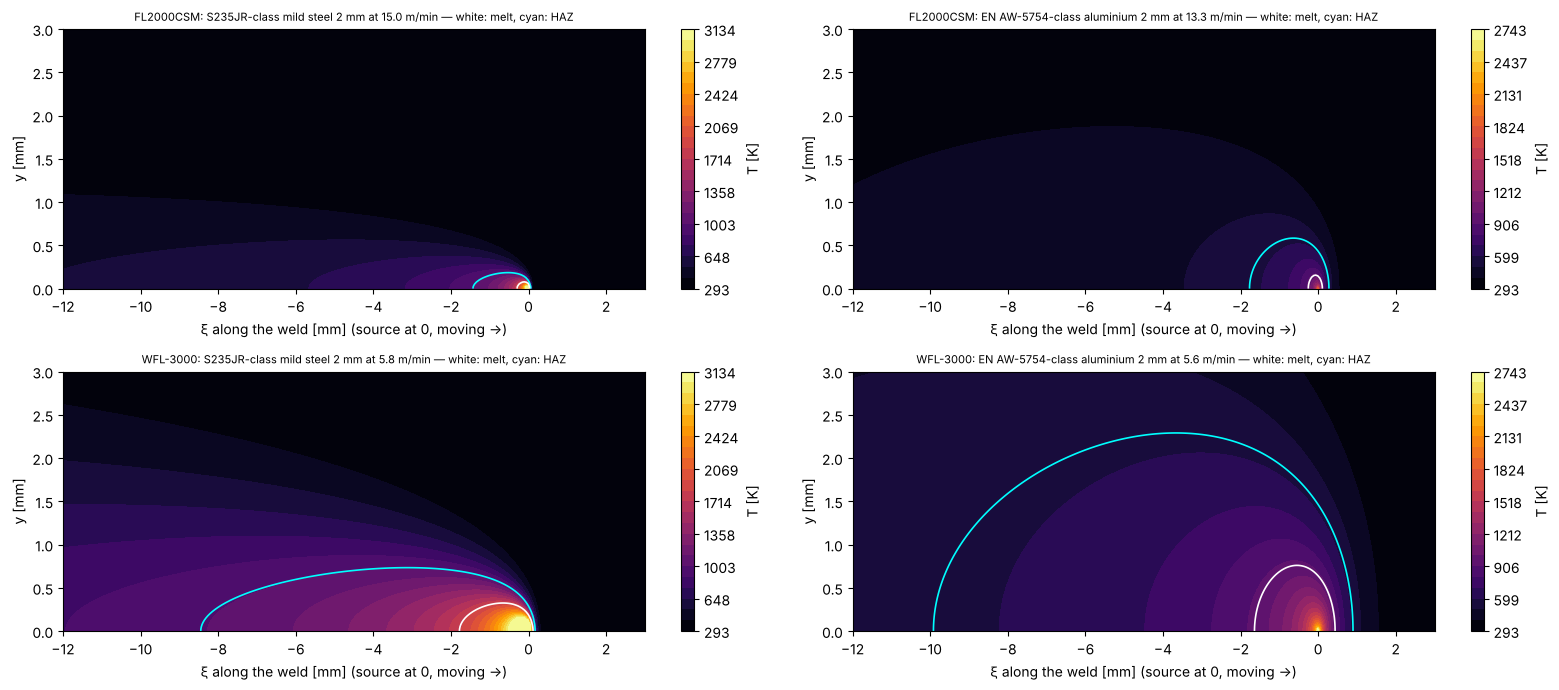

material  t [mm]  v [m/min]  solidification [ms]  t8/5 [s]  cooling rate at melt [K/s]  gradient at fusion [K/mm]  HAZ each side [mm]  distortion index [K]  humping risk  keyhole marginal
YLS-SM    0     S235JR-class mild steel     1.0     47.892                0.481     0.005                 1405584.123                  31883.889               0.065               346.146          True             False
          1     S235JR-class mild steel     2.0     15.994                1.038     0.016                  627057.116                  13808.851               0.100               259.122          True             False
          2     S235JR-class mild steel     3.0      8.075                1.705     0.031                  359606.989                  13227.013               0.135               228.114          True             False
          3  EN AW-5754-class aluminium     1.0     49.932                0.424     0.001                  530227.462                   4108.883               0.226               435.454          True             False
          4  EN AW-5754-class aluminium     2.0     14.237                0.998     0.002                  172419.932                   2090.516               0.401               381.812          True             False
          5  EN AW-5754-class aluminium     3.0      6.651                1.412     0.005                   84671.934                   2004.217               0.535               363.231          True             False
FL2000C   0     S235JR-class mild steel     1.0      8.971               13.719     0.086                   49323.062                   4902.221               0.346              1847.834          True             False
          1     S235JR-class mild steel     2.0      2.996               29.587     0.193                   22003.932                   3391.524               0.534              1383.273         False             False
          2     S235JR-class mild steel     3.0      1.513               48.589     0.337                   12618.895                   2506.835               0.722              1217.744         False             False
          3  EN AW-5754-class aluminium     1.0      9.354               12.081     0.015                   18606.102                    701.198               1.205              2324.588          True             False
          4  EN AW-5754-class aluminium     2.0      2.667               28.448     0.046                    6050.352                    428.055               2.139              2038.231         False             False
          5  EN AW-5754-class aluminium     3.0      1.246               40.251     0.093                    2971.205                    376.340               2.854              1939.037         False             False
FL2000CSM 0     S235JR-class mild steel     1.0     44.857                0.549     0.006                 1233076.555                  33570.491               0.069               369.567          True             False
          1     S235JR-class mild steel     2.0     14.980                1.183     0.017                  550098.295                  14426.199               0.107               276.655          True             False
          2     S235JR-class mild steel     3.0      7.563                1.944     0.033                  315472.365                  13598.063               0.144               243.549          True             False
          3  EN AW-5754-class aluminium     1.0     46.768                0.483     0.001                  465152.560                   2933.373               0.241               464.918          True             False
          4  EN AW-5754-class aluminium     2.0     13.335                1.138     0.003                  151258.806                   2117.810               0.428               407.646          True             False
          5  EN AW-5754-class aluminium     3.0      6.230                1.610     0.006

material  t [mm]  speed spread [%]                                                                                   hangs on                                             field model validated
YLS-SM    0     S235JR-class mild steel     1.0              87.9  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          1     S235JR-class mild steel     2.0             132.2  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          2     S235JR-class mild steel     3.0             137.7  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          3  EN AW-5754-class aluminium     1.0              89.0  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          4  EN AW-5754-class aluminium     2.0             165.5  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          5  EN AW-5754-class aluminium     3.0             169.4  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
FL2000C   0     S235JR-class mild steel     1.0             122.5  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          1     S235JR-class mild steel     2.0             132.2  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          2     S235JR-class mild steel     3.0             137.7  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          3  EN AW-5754-class aluminium     1.0             156.7  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          4  EN AW-5754-class aluminium     2.0             165.5  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          5  EN AW-5754-class aluminium     3.0             169.4  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
FL2000CSM 0     S235JR-class mild steel     1.0              96.4  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          1     S235JR-class mild steel     2.0             132.2  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          2     S235JR-class mild steel     3.0             137.7  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          3  EN AW-5754-class aluminium     1.0              97.1  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          4  EN AW-5754-class aluminium     2.0             165.5  keyhole absorptivity, melting efficiency (the two numbers a trial recalibrates: svarog...  thin-plate line source, no losses, constant properties        no
          5  EN A

defects to expect:


,alloy,defect drivers
steel,"S235JR / DC01 (unalloyed low-carbon sheet, uncoated); a zinc coating is a separate def...",zinc outgassing if coated; hardness in the HAZ at short t8/5 (low carbon: tolerant); h...
aluminium,"EN AW-5754 (AlMg3, H22/H111); 6082 would add hot-cracking sensitivity and need 4043/53...","hydrogen porosity (oxide, moisture); keyhole collapse porosity; magnesium loss and spa..."


In [7]:
fig, axs = plt.subplots(2, 2, figsize=(16, 7))
for ax, (k, fam) in zip(axs.flat, (("FL2000CSM", "steel"), ("FL2000CSM", "aluminium"), ("WFL-3000", "steel"), ("WFL-3000", "aluminium"))):
    case = next(c for c in WELDS[k] if c["family"] == fam and c["thickness"] == 2e-3)
    scd.thermal_field_view(case, ax=ax)
plt.tight_layout(); plt.savefig(OUT / "thermal_fields.png", dpi=110); plt.show()
COOL = pd.concat(WT)[["material", "t [mm]", "v [m/min]", "solidification [ms]", "t8/5 [s]", "cooling rate at melt [K/s]", "gradient at fusion [K/mm]", "HAZ each side [mm]", "distortion index [K]", "humping risk", "keyhole marginal"]]
display(COOL.round(3))
UNC = pd.concat({k: sc.welding_uncertainty(v) for k, v in WELDS.items()}).drop(columns=["laser"]); display(UNC.round(1))
print("defects to expect:"); display(pd.DataFrame({fam: {"alloy": m["alloy"], "defect drivers": m["defects"]} for fam, m in sc.SHEET_MATERIALS.items()}).T)

## 5. Shielding — accidental exposure at 5, 10, 20, 50 and 100 m

The question is not "how long does the panel last" but "could this panel ever be shown to protect": the four lasers against three
families — polycarbonate (clear, opaque, certified laser-protective), aluminium (bare, oxidised, coated), wood (solid, plywood,
fire-retardant) — at five distances, under the **raw collimated beam** (the full delivered power escaping before the focusing optic
or re-collimated by a reflector: the worst case, a beam that grows only by its own divergence) and under a **specular reflection**
off the workpiece (the beam through the focus, 0.9 × the power, diverging at the head's cone). The base matrix is 4 lasers × 5
distances × 3 families = 60 cases (the first variant of each family); the variants make 180. Standards: IEC 60825-1 (the MPE),
IEC 60825-4 (the guard's exposure classes T1/T2/T3), ISO 11553-1 (the machine), EN 12254 (screens: protection levels AB1–AB10),
EN 207 (the LB ladder) — the constants below are read from the editions named in `sc.STANDARDS`; **verify the current ones**.
Distance alone never establishes safety; no burn-through time is computed.

### 5.1 Propagation and exposure

The beam's radius and mean irradiance at the barrier, against the eye's MPE at 1070 nm (50 W/m² from 10 s on, 90 t^−0.25 W/m²
below) and the skin's (10 kW/m²), the nominal ocular hazard distance of the collimated and the diverging beam, and the optical
density a window or eyewear would need (OD = log₁₀ E/MPE, with EN 207's D-mode scale number as the ladder).

60 base cases (collimated beam), 180 with the material variants, 360 with the reflected beam; exposure class T2 (100 s) for the MPE


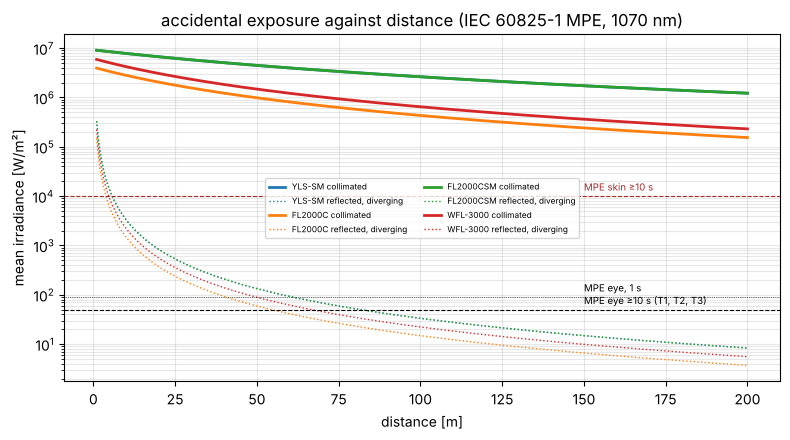

beam_radius_mm                         en207_lb_scale                         irradiance_W_per_cm2                                 od_required                         over_mpe_eye                                           over_mpe_skin  \
distance_m          5.0   10.0  20.0  50.0  100.0          5.0   10.0  20.0  50.0  100.0                5.0     10.0    20.0    50.0    100.0       5.0   10.0  20.0  50.0  100.0        5.0        10.0       20.0      50.0      100.0         5.0     
laser                                                                                                                                                                                                                                                    
FL2000C             13.25  14.5  17.0  24.5  37.0            4.0   4.0   4.0   3.0   3.0               337.06  281.45  204.76   98.58   43.23        4.83  4.75  4.61  4.29  3.94     67412.35   56290.51   40951.83  19716.92   8645.05        337.06   
FL2000CSM            8.35   8.7   9.4  11.5  15.0            4.0   4.0   4.0   4.0   4.0               848.73  781.81  669.71  447.45  263.00        5.23  5.19  5.13  4.95  4.72    169745.49  156362.53  133941.60  89490.21  52600.36        848.73   
WFL-3000            13.25  14.5  17.0  24.5  37.0            4.0   4.0   4.0   4.0   3.0               505.59  422.18  307.14  147.88   64.84        5.00  4.93  4.79  4.47  4.11    101118.52   84435.77   61427.75  29575.38  12967.58        505.59   
YLS-SM               8.35   8.7   9.4  11.5  15.0            4.0   4.0   4.0   4.0   4.0               848.73  781.81  669.71  447.45  263.00        5.23  5.19  5.13  4.95  4.72    169745.49  156362.53  133941.60  89490.21  52600.36        848.73   

                                            
distance_m   10.0    20.0    50.0    100.0  
laser                                       
FL2000C     281.45  204.76   98.58   43.23  
FL2000CSM   781.81  669.71  447.45  263.00  
WFL-3000    422.18  307.14  147.88   64.84  
YLS-SM      781.81  669.71  447.45  263.00

,NOHD collimated [km],"NOHD reflected, diverging [m]","NOHD skin, collimated [m]"
IPG YLS-SM,49.0,86.0,3360.9
Coherent FL2000C,13.7,57.3,925.0
Coherent FL2000CSM,49.0,86.0,3360.9
nLIGHT WFL-3000,16.8,70.2,1143.7


the reflected (diverging) beam at the barrier:


beam_radius_mm                                irradiance_W_per_cm2                             over_mpe_eye                              
distance_m          5.0    10.0    20.0    50.0    100.0                5.0    10.0   20.0   50.0   100.0        5.0     10.0    20.0   50.0   100.0
laser                                                                                                                                               
FL2000C             300.0  600.0  1200.0  3000.0  6000.0                0.592  0.148  0.037  0.006  0.001      118.351  29.588   7.397  1.184  0.296
FL2000CSM           200.0  400.0   800.0  2000.0  4000.0                1.331  0.333  0.083  0.013  0.003      266.289  66.572  16.643  2.663  0.666
WFL-3000            300.0  600.0  1200.0  3000.0  6000.0                0.888  0.222  0.055  0.009  0.002      177.526  44.382  11.095  1.775  0.444
YLS-SM              200.0  400.0   800.0  2000.0  4000.0                1.331  0.333  0.083  0.013  0.003      266.289  66.572  16.643  2.663  0.666

In [8]:
SH = sc.shield_cases(variants=True, kinds=("collimated", "reflected"), exposure="T2")
BASE = SH[SH["base"] & (SH["beam"] == "collimated")]
assert len(BASE) == 60 and len(SH[SH["beam"] == "collimated"]) == 180, (len(BASE), len(SH))
print(f"{len(BASE)} base cases (collimated beam), {len(SH[SH['beam'] == 'collimated'])} with the material variants, {len(SH)} with the reflected beam; exposure class T2 (100 s) for the MPE")
scd.exposure_view(OPT); plt.tight_layout(); plt.savefig(OUT / "exposure.png", dpi=110); plt.show()
EXP = BASE[BASE["family"] == "polycarbonate"].pivot_table(index="laser", columns="distance_m", values=["beam_radius_mm", "irradiance_W_per_cm2", "over_mpe_eye", "over_mpe_skin", "od_required", "en207_lb_scale"])
display(EXP.round(2))
NOHD = pd.DataFrame({sc.LASERS[k].name: {"NOHD collimated [km]": sc.nohd(OPT[k]) / 1e3, "NOHD reflected, diverging [m]": sc.nohd(OPT[k], kind="reflected"), "NOHD skin, collimated [m]": sc.nohd(OPT[k], 1e4)} for k in sc.LASERS}).T
display(NOHD.round(1))
print("the reflected (diverging) beam at the barrier:"); display(SH[(SH['beam'] == 'reflected') & SH['base'] & (SH['family'] == 'polycarbonate')].pivot_table(index='laser', columns='distance_m', values=['beam_radius_mm', 'irradiance_W_per_cm2', 'over_mpe_eye']).round(3))

### 5.2 The barriers' non-destructive thermal response

What each panel does with the beam: the transmitted share (clear polycarbonate passes ~80 % — it is no barrier at 1 µm; the
certified sheet's dye absorbs within tenths of a millimetre), the reflected share (bare aluminium sends ~90 % elsewhere: the
hazard moves, it does not vanish), and the absorbed irradiance against **bounds** that never model damage: the semi-infinite
surface rise at T1 and T2 (an upper bound for a thick, lossless solid), the lumped plate's rise at T1, and the steady upper bound
with the edge cold (`si.plate_steady_bound`). `bound_ratio` is the smallest bound over the damage rise (melting; charring for the
plastics and wood): below 1 the closed forms say the damage point cannot be reached; above 1 nothing is concluded — a bound is
not a prediction, and only a certified test decides. Wood adds a fire-risk indicator: the absorbed flux against the piloted
(10–13 kW/m²) and unpiloted (25–30 kW/m²) ignition fluxes of the fire-safety handbooks. Book fenix's F4 runs (steady finite
elements of the same panels) are cross-referenced where they exist.

bound ratio (smallest closed-form bound / damage rise; < 1: cannot reach damage by these bounds; ≥ 1: no conclusion)


distance_m                                          5.0    10.0   20.0   50.0   100.0
laser     family        variant                                                      
FL2000C   aluminium     bare                         0.10   0.08   0.06   0.03   0.01
                        coated                       0.58   0.49   0.35   0.17   0.07
                        oxidised                     0.21   0.17   0.13   0.06   0.03
          polycarbonate certified laser-protective   9.69   8.09   5.88   2.83   1.24
                        clear                        9.69   8.09   5.88   2.83   1.24
                        opaque                      10.00   8.35   6.08   2.93   1.28
          wood          fire-retardant               5.55   4.63   3.37   1.62   0.71
                        plywood                      5.04   4.21   3.06   1.47   0.65
                        solid                        6.16   5.15   3.74   1.80   0.79
FL2000CSM aluminium     bare                         0.25   0.23   0.20   0.13   0.08
                        coated                       1.46   1.35   1.15   0.77   0.45
                        oxidised                     0.52   0.48   0.41   0.28   0.16
          polycarbonate certified laser-protective  24.39  22.47  19.25  12.86   7.56
                        clear                       24.39  22.47  19.25  12.86   7.56
                        opaque                      25.19  23.20  19.87  13.28   7.80
          wood          fire-retardant              13.96  12.86  11.02   7.36   4.33
                        plywood                     12.70  11.69  10.02   6.69   3.93
                        solid                       15.52  14.29  12.24   8.18   4.81
WFL-3000  aluminium     bare                         0.15   0.12   0.09   0.04   0.02
                        coated                       0.87   0.73   0.53   0.25   0.11
                        oxidised                     0.31   0.26   0.19   0.09   0.04
          polycarbonate certified laser-protective  14.53  12.13   8.83   4.25   1.86
                        clear                       14.53  12.13   8.83   4.25   1.86
                        opaque                      15.00  12.53   9.11   4.39   1.92
          wood          fire-retardant               8.32   6.95   5.05   2.43   1.07
                        plywood                      7.56   6.31   4.59   2.21   0.97
                        solid                        9.24   7.72   5.62   2.70   1.19
YLS-SM    aluminium     bare                         0.25   0.23   0.20   0.13   0.08
                        coated                       1.46   1.35   1.15   0.77   0.45
                        oxidised                     0.52   0.48   0.41   0.28   0.16
          polycarbonate certified laser-protective  24.39  22.47  19.25  12.86   7.56
                        clear                       24.39  22.47  19.25  12.86   7.56
                        opaque                      25.19  23.20  19.87  13.28   7.80
          wood          fire-retardant              13.96  12.86  11.02   7.36   4.33
                        plywood                     12.70  11.69  10.02   6.69   3.93
                        solid                       15.52  14.29  12.24   8.18   4.81

absorbed_irradiance_W_per_cm2                             reflected_fraction                           transmitted_fraction                          
laser                                                          FL2000C FL2000CSM WFL-3000   YLS-SM            FL2000C FL2000CSM WFL-3000 YLS-SM              FL2000C FL2000CSM WFL-3000 YLS-SM
family        variant                                                                                                                                                                         
aluminium     bare                                              33.774    93.818   50.661   93.818               0.88      0.88     0.88   0.88                0.000     0.000    0.000  0.000
              coated                                           197.017   547.269  295.525  547.269               0.30      0.30     0.30   0.30                0.000     0.000    0.000  0.000
              oxidised                                          70.363   195.453  105.545  195.453               0.75      0.75     0.75   0.75                0.000     0.000    0.000  0.000
polycarbonate certified laser-protective                       258.936   719.268  388.405  719.268               0.08      0.08     0.08   0.08                0.000     0.000    0.000  0.000
              clear                                            258.936   719.268  388.405  719.268               0.00      0.00     0.00   0.00                0.817     0.817    0.817  0.817
              opaque                                           267.380   742.722  401.070  742.722               0.05      0.05     0.05   0.05                0.000     0.000    0.000  0.000
wood          fire-retardant                                   168.872   469.088  253.307  469.088               0.40      0.40     0.40   0.40                0.000     0.000    0.000  0.000
              plywood                                          168.872   469.088  253.307  469.088               0.40      0.40     0.40   0.40                0.000     0.000    0.000  0.000
              solid                                            168.872   469.088  253.307  469.088               0.40      0.40     0.40   0.40                0.000     0.000    0.000  0.000

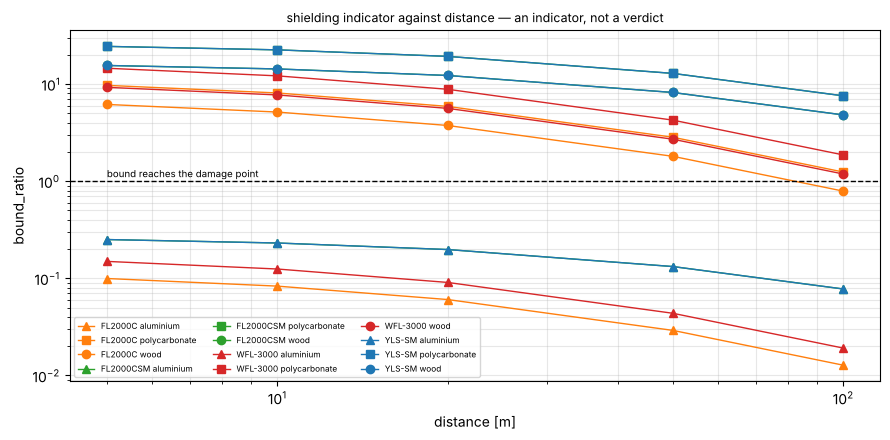

wood: fire-risk indicator


distance_m                                                  5.0                                      10.0                                     20.0                                     50.0                                     100.0
laser     variant                                                                                                                                                                                                                    
FL2000C   fire-retardant  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux
          plywood         high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux
          solid           high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux
FL2000CSM fire-retardant  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux
          plywood         high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux
          solid           high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux
WFL-3000  fire-retardant  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux
          plywood         high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux
          solid           high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux
YLS-SM    fire-retardant  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux
          plywood         high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux
          solid           high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux  high: above the unpiloted-ignition flux

F4 shield-steady @YLS-SM: NOT RUN (wf run F4 --variant YLS-SM on a machine with the fenicsx interpreter)
F4 shield-steady @FL2000C: NOT RUN (wf run F4 --variant FL2000C on a machine with the fenicsx interpreter)
F4 shield-steady @FL2000CSM: NOT RUN (wf run F4 --variant FL2000CSM on a machine with the fenicsx interpreter)
F4 shield-steady @WFL-3000: NOT RUN (wf run F4 --variant WFL-3000 on a machine with the fenicsx interpreter)


In [9]:
RESP = SH[(SH["beam"] == "collimated")].pivot_table(index=["laser", "family", "variant"], columns="distance_m", values="bound_ratio")
print("bound ratio (smallest closed-form bound / damage rise; < 1: cannot reach damage by these bounds; ≥ 1: no conclusion)"); display(RESP.round(2))
SHARES = SH[(SH["beam"] == "collimated") & (SH["distance_m"] == 10.0)].pivot_table(index=["family", "variant"], columns="laser", values=["transmitted_fraction", "reflected_fraction", "absorbed_irradiance_W_per_cm2"])
display(SHARES.round(3))
scd.risk_vs_distance_view(SH); plt.tight_layout(); plt.savefig(OUT / "risk_vs_distance.png", dpi=110); plt.show()
FIRE = SH[(SH["beam"] == "collimated") & (SH["family"] == "wood")].pivot_table(index=["laser", "variant"], columns="distance_m", values="fire_risk", aggfunc="first")
print("wood: fire-risk indicator"); display(FIRE)
F4 = {}
for k in sc.LASERS:
    run, root = fenix(k)
    F4[k] = root
    if not run:
        print(f"F4 shield-steady @{k}: NOT RUN (wf run F4 --variant {k} on a machine with the fenicsx interpreter)"); continue
    rows = []
    for _, r in SH[(SH["beam"] == "collimated") & (SH["laser"] == k)].iterrows():
        name = f"{(r['family'] + '_' + r['variant']).replace(' ', '_').replace('-', '_').replace('.', 'p')}_at_{int(r['distance_m'])}m"      # plate_thermal.cases_of's case names
        c = (run.get("cases") or {}).get(name, {})
        rows.append({"barrier": r["barrier"], "distance_m": r["distance_m"], "closed-form steady bound [K]": r["steady_rise_bound_K"], "FEM steady T_max [K]": c.get("T_max"), "FEM reaches damage": c.get("reaches_damage"), "status": c.get("status", "NOT RUN")})
    print(f"F4 shield-steady @{k}: {run.get('counts')} ({run.get('fenicsx')}, {run.get('quality')})"); display(pd.DataFrame(rows).round(1))

### 5.3 Degraded barriers, seams, reflections, interlocks

A barrier as it is, not as it was bought: the certified sheet with its transmission grown ×1–5 (scratched, crazed, thinned — no
product data, a sensitivity), aluminium across its absorptivity span (0.12 polished to 0.7 painted: the reflected share and the
heating trade places), a seam between panels (a 1 mm gap passes the strip of beam that meets it: a geometry failure regardless of
material), and the specular reflection that moves the hazard to another wall. Every case carries `interlock_required = True`: a
Class 4 source is enclosed by a guard with interlocked access (IEC 60825-1 / ISO 11553-1), or it is not enclosed at all.

In [10]:
print("FL2000C at 10 m, the certified sheet degraded and aluminium across its surfaces:"); display(sc.degraded_sensitivity(sc.LASERS["FL2000C"], 10.0).round(3))
SEAM = BASE[BASE["family"] == "polycarbonate"].pivot_table(index="laser", columns="distance_m", values=["seam_share", "seam_power_W"])
print(f"a {sc.ASSUMPTIONS['seam_gap_mm'].nominal:g} mm seam across the beam: the share and the watts through it"); display(SEAM.round(3))
REFL = SH[(SH["beam"] == "reflected") & SH["base"]].pivot_table(index=["laser", "family"], columns="distance_m", values="bound_ratio")
print("the reflected (diverging) beam's bound ratio: metres wide, harmless to panels — the eye is another matter (5.1)"); display(REFL.round(4))

FL2000C at 10 m, the certified sheet degraded and aluminium across its surfaces:


,barrier,transmitted [%],verdict,reason,steady bound [K],reflected [W]
0,"certified, transmission ×1",0.000,INCOMPLETE,needs the product's EN 12254 level for 281.5 W/cm² over 100 s,NaN,NaN
1,"certified, transmission ×2",0.022,INCOMPLETE,needs the product's EN 12254 level for 281.5 W/cm² over 100 s,NaN,NaN
2,"certified, transmission ×5",3.220,FAIL,transmits 3 % at 1 µm,NaN,NaN
3,absorptivity 0.12,0.000,INCOMPLETE,"the closed-form bounds stay under the damage point, but a bound is not a test: certify...",417.735,1635.964
4,absorptivity 0.25,0.000,INCOMPLETE,"the closed-form bounds stay under the damage point, but a bound is not a test: certify...",870.281,1394.288
5,absorptivity 0.7,0.000,INCOMPLETE,"the closed-form bounds stay under the damage point, but a bound is not a test: certify...",2436.787,557.715


a 1 mm seam across the beam: the share and the watts through it


seam_power_W                                    seam_share                            
distance_m        5.0      10.0     20.0     50.0    100.0      5.0    10.0   20.0   50.0   100.0
laser                                                                                            
FL2000C          89.321   81.621   69.618   48.306  31.987      0.048  0.044  0.037  0.026  0.017
FL2000CSM       141.737  136.035  125.905  102.914  78.901      0.076  0.073  0.068  0.055  0.042
WFL-3000        133.982  122.432  104.427   72.460  47.980      0.048  0.044  0.037  0.026  0.017
YLS-SM          141.737  136.035  125.905  102.914  78.901      0.076  0.073  0.068  0.055  0.042

the reflected (diverging) beam's bound ratio: metres wide, harmless to panels — the eye is another matter (5.1)


distance_m                5.0     10.0    20.0    50.0    100.0
laser     family                                               
FL2000C   aluminium      0.0002  0.0000  0.0000  0.0000  0.0000
          polycarbonate  0.0170  0.0043  0.0011  0.0002  0.0000
          wood           0.0108  0.0027  0.0007  0.0001  0.0000
FL2000CSM aluminium      0.0004  0.0001  0.0000  0.0000  0.0000
          polycarbonate  0.0383  0.0096  0.0024  0.0004  0.0001
          wood           0.0243  0.0061  0.0015  0.0002  0.0001
WFL-3000  aluminium      0.0003  0.0001  0.0000  0.0000  0.0000
          polycarbonate  0.0255  0.0064  0.0016  0.0003  0.0001
          wood           0.0162  0.0041  0.0010  0.0002  0.0000
YLS-SM    aluminium      0.0004  0.0001  0.0000  0.0000  0.0000
          polycarbonate  0.0383  0.0096  0.0024  0.0004  0.0001
          wood           0.0243  0.0061  0.0015  0.0002  0.0001

### 5.4 Verdicts

**PASS** only with certified protection evidence (a product's EN 12254 level, or an IEC 60825-4 test, covering this irradiance and
exposure class) — evidence this notebook does not hold, so every PASS below would have to be entered by hand (`evidence = "certified"`);
**FAIL** when the panel transmits more than 1 % or a seam passes the beam; **INCOMPLETE** otherwise, whether the closed-form bounds
stay under the damage point (a bound is not a test) or exceed it (no safety can be claimed). A simulation cannot certify a barrier.

distance_m                                               5.0         10.0        20.0        50.0        100.0
laser     family        variant                                                                               
FL2000C   aluminium     bare                        INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        coated                      INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        oxidised                    INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
          polycarbonate certified laser-protective  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        clear                             FAIL        FAIL        FAIL        FAIL        FAIL
                        opaque                      INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
          wood          fire-retardant              INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        plywood                     INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        solid                       INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
FL2000CSM aluminium     bare                        INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        coated                      INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        oxidised                    INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
          polycarbonate certified laser-protective  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        clear                             FAIL        FAIL        FAIL        FAIL        FAIL
                        opaque                      INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
          wood          fire-retardant              INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        plywood                     INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        solid                       INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
WFL-3000  aluminium     bare                        INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        coated                      INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        oxidised                    INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
          polycarbonate certified laser-protective  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        clear                             FAIL        FAIL        FAIL        FAIL        FAIL
                        opaque                      INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
          wood          fire-retardant              INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        plywood                     INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        solid                       INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
YLS-SM    aluminium     bare                        INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        coated                      INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        oxidised                    INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
          polycarbonate certified laser-protective  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
                        clear                             FAIL        FAIL        FAIL        FAIL        FAIL
                        opaque                      INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
          wood          fire-retardant              INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE  INCOMPLETE
    

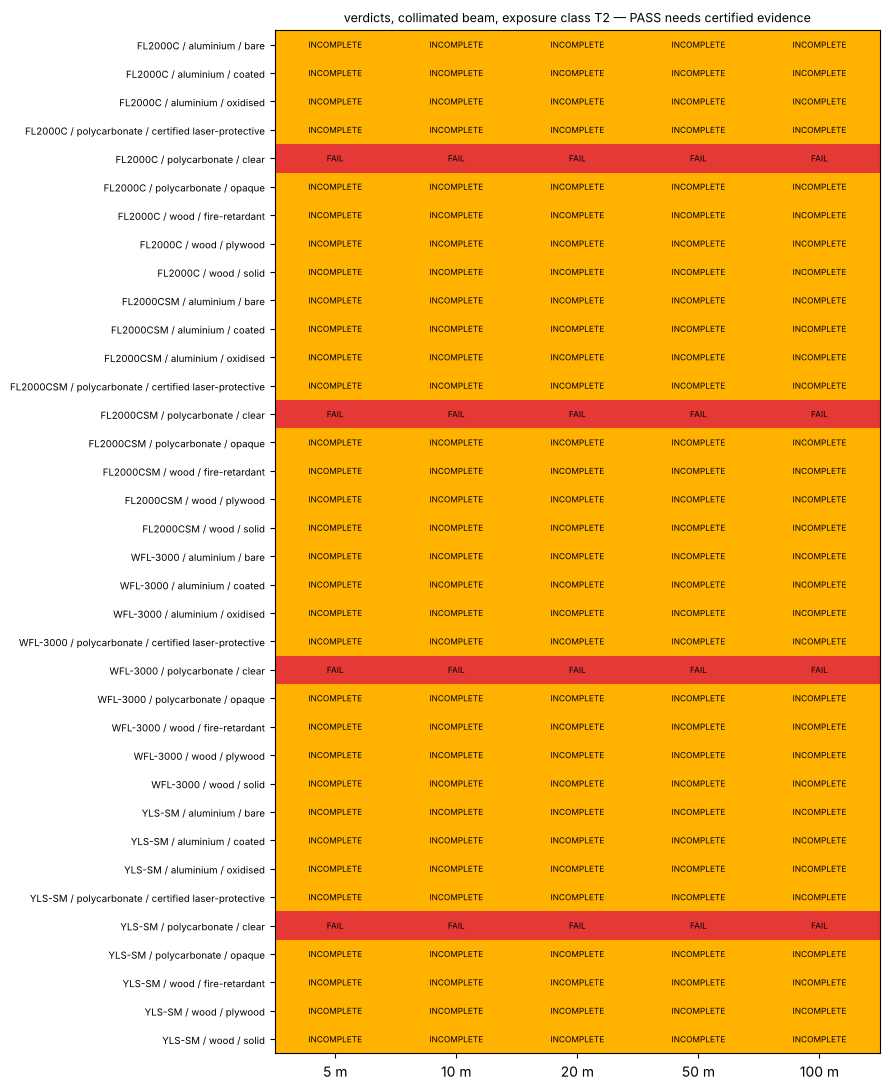

verdict,FAIL,INCOMPLETE
base,,
False,0,120
True,20,40


reasons:


family         variant                     verdict   
aluminium      bare                        INCOMPLETE    the closed-form bounds stay under the damage point, but a bound is not a test: certify...
               coated                      INCOMPLETE    the bounds exceed the damage point: no safety can be claimed; a tested barrier is requ...
               oxidised                    INCOMPLETE    the closed-form bounds stay under the damage point, but a bound is not a test: certify...
polycarbonate  certified laser-protective  INCOMPLETE                                needs the product's EN 12254 level for 848.7 W/cm² over 100 s
               clear                       FAIL                                                                             transmits 82 % at 1 µm
               opaque                      INCOMPLETE    the bounds exceed the damage point: no safety can be claimed; a tested barrier is requ...
wood           fire-retardant              INCOMPLETE    the bou

In [11]:
VM = sc.verdict_matrix(SH[SH["base"]]); VMV = sc.verdict_matrix(SH)
display(VMV)
fig, ax = plt.subplots(figsize=(9, 11)); scd.verdict_matrix_view(VMV, ax=ax, title="verdicts, collimated beam, exposure class T2 — PASS needs certified evidence")
plt.tight_layout(); plt.savefig(OUT / "verdicts.png", dpi=110); plt.show()
COUNTS = SH[SH["beam"] == "collimated"].groupby(["base", "verdict"]).size().unstack(fill_value=0); display(COUNTS)
assert "PASS" not in COUNTS.columns, "no certified evidence was entered: a PASS cannot appear"
print("reasons:"); display(SH[SH["beam"] == "collimated"].groupby(["family", "variant", "verdict"])["reason"].first())

### 5.5 How long a shield stands — the guard designer's number (recorded)

Notebook 46 Part IV §3's question asked of the commercial lasers: a sheet of polycarbonate (black), mild steel or aluminium at
1, 2 and 3 mm under the raw collimated beam at 5, 10, 20, 50 and 100 m — how long before the beam is through. The route is 46's
(`sc.endurance`): `si.screen`'s closed forms first (a transparent sheet: 0 s; a steady or energy bound: for ever; else the steady
solve), the enthalpy/ablation cell transient (`th.heat_plate`, the grid ending at a 60 × 60 cm sheet's edge, capped at 3000 s)
only where the screening cannot decide, `si.verdict` for `holds_s` and the IEC 60825-4 classes T1 (10 s), T2 (100 s), T3
(30 000 s). Minutes per laser, so it is **recorded** — `python designs/svarog_commercial.py --endurance` writes
`designs/data/svarog_commercial_endurance.json` with its provenance, and this cell only reads it (NOT RUN when absent). The time a
panel buys is a design number, no part of §5.4's verdicts: a cell-model time certifies nothing.

In [12]:
END = sc.load_endurance()
if END is None:
    print("NOT RUN — designs/data/svarog_commercial_endurance.json is missing: run  python designs/svarog_commercial.py --endurance  (minutes per laser)")
    ENDT = None
else:
    m = END["meta"]; print(f"recorded {m['made']} (screening grid: {m['screening']}, nr {m['grid']['nr']}, cap {m['grid']['t_max_s']:g} s) — {m['caveat']}")
    ENDR = [r for rs in END["rows"].values() for r in rs]
    ENDT = sc.endurance_table(ENDR); display(ENDT.round(1))
    ENDF = pd.DataFrame(ENDR)
    print("decided by:"); display(ENDF.groupby(["family", "source"]).size())
    CLS = ENDF.pivot_table(index=["laser", "family", "thickness_mm"], columns="distance_m", values=["T1", "T2", "T3"], aggfunc="first")
    display(CLS)
    fig, axs = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
    for ax, fam in zip(axs, sc.ENDURANCE_SHEETS):
        for k in sc.LASERS:
            for t_mm, ls in ((1.0, ":"), (2.0, "--"), (3.0, "-")):
                sub = ENDF[(ENDF["laser"] == k) & (ENDF["family"] == fam) & (ENDF["thickness_mm"] == t_mm)].sort_values("distance_m")
                ax.plot(sub["distance_m"], sub["holds_s"].replace(np.inf, 1e5), ls, marker="o", color=scd.COL.get(k, "k"), label=f"{k} {t_mm:g} mm")
        for t, name in sc.EXPOSURE.items():
            ax.axhline(name, color="grey", lw=0.8, ls="--"); ax.text(5.2, name * 1.3, t, fontsize=7)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("distance [m]"); ax.set_title(f"{fam}: time the sheet holds (1e5 = for ever by a bound)", fontsize=9); ax.grid(alpha=0.3, which="both")
    axs[0].set_ylabel("holds [s]"); axs[-1].legend(fontsize=6, ncol=2)
    plt.tight_layout(); plt.savefig(OUT / "endurance.png", dpi=110); plt.show()

NOT RUN — designs/data/svarog_commercial_endurance.json is missing: run  python designs/svarog_commercial.py --endurance  (minutes per laser)


### 5.6 The economics — sourced parameters against the welds and the shields

The first allowances were a guess (kept in the specs file's `prices` as the record); the calculations use `economics`: parameters
looked up on 2026-10-17 — no maker publishes a source price, so the source's capex spans a used YLR-2000-SM listing (€18.5 k) to
the reported original price of a 2014 YLS-2000 (€90 k) around a buyer's-guide mid (€50 k); heads €1.2–5.3 k and chillers €1.2–3.9 k
from retail listings; electricity at Eurostat's non-household H2 2025 figures (EU €0.184/kWh, Finland 0.075, Ireland 0.255); labour at
Eurostat's 2025 hourly cost (EU €34.9, economy-wide); argon at cylinder-refill prices (≈ €48/m³ — bulk is forty times cheaper);
diode life 20 000–100 000 h; steel at the NW-European HRC price; the certified sheet at the retail price of 1064 nm safety acrylic;
the rest assumed and marked so. Three results: the **cost per metre of weld** (the hourly cost over the model speed, arc-on time
only: a lower bound), the **shield an escape needs** (for a person who needs 1, 3 or 5 s to leave the beam's path, the thinnest
recorded sheet of §5.5 that holds that long, its cost per m², and that cost per thousand euro of the source: the dearer source's
burden), and the **escape seconds per euro** of each panel. Ratios of an unvalidated model and listed prices: they rank, they do not price.

In [13]:
print(sc.ECON["note"]); display(sc.econ_table())
CAPEX = pd.DataFrame({sc.LASERS[k].name: {f"{part} [k€] {lvl}": sc.capex(sc.LASERS[k])[lvl][part] / 1e3 for lvl in ("low", "nominal", "high") for part in ("source", "head", "chiller", "total")} for k in sc.LASERS}).T
display(CAPEX.round(1))
OPEX = pd.DataFrame({sc.LASERS[k].name: {f"{part} [€/h] {lvl}": sc.opex_per_hour(sc.LASERS[k], ENERGY[k])[lvl][part] for lvl in ("low", "nominal", "high") for part in ("electricity", "gas", "maintenance", "diodes", "labour", "total")} for k in sc.LASERS}).T
display(OPEX.round(2))
CPM = pd.concat([sc.cost_per_metre(WELDS[k], ENERGY[k]) for k in sc.LASERS], ignore_index=True)
print("cost per metre of weld (arc-on time only; model speed):"); display(CPM.drop(columns=["basis"]).round(3))
if END is None:
    print("shield economics: NOT RUN (the endurance record is missing)"); NEED = PEREUR = None
else:
    NEED, PEREUR = sc.shield_economics(ENDR)
    print("the shield an escape needs — the thinnest recorded sheet holding 1 / 3 / 5 s — its cost per m² and per k€ of source:")
    display(NEED.pivot_table(index=["laser", "family", "escape_s"], columns="distance_m", values="shield_label", aggfunc="first"))
    display(NEED.pivot_table(index=["laser", "family", "escape_s"], columns="distance_m", values="panel € per k€ of source").round(2))
    print("escape seconds per euro of panel (per m²; inf: holds for ever by a bound):")
    display(PEREUR.pivot_table(index=["laser", "family", "thickness_mm"], columns="distance_m", values="escape s per € of panel", dropna=False).round(2))
    fig, axs = plt.subplots(1, 3, figsize=(20, 4.5))
    for k in sc.LASERS:
        sub = CPM[(CPM["laser"] == k) & CPM["material"].str.contains("steel")]
        axs[0].plot(sub["t [mm]"], sub["€/m with operator"], "-o", color=scd.COL[k], label=f"{k} steel")
        sub = CPM[(CPM["laser"] == k) & CPM["material"].str.contains("aluminium")]
        axs[0].plot(sub["t [mm]"], sub["€/m with operator"], "--s", color=scd.COL[k], label=f"{k} aluminium")
        sub = NEED[(NEED["laser"] == k) & (NEED["family"] == "steel") & (NEED["escape_s"] == 3.0)]
        axs[1].plot(sub["distance_m"], sub["panel € per k€ of source"], "-s", color=scd.COL[k], label=f"{k} steel, 3 s escape")
        sub = PEREUR[(PEREUR["laser"] == k) & (PEREUR["family"] == "polycarbonate") & (PEREUR["thickness_mm"] == 3.0)]
        axs[2].plot(sub["distance_m"], sub["escape s per € of panel"], "-o", color=scd.COL[k], label=f"{k} black PC 3 mm")
    axs[0].set_xlabel("sheet [mm]"); axs[0].set_ylabel("€/m (with operator)"); axs[0].set_title("cost per metre of weld — arc-on time, model speed", fontsize=9); axs[0].grid(alpha=0.3); axs[0].legend(fontsize=6, ncol=2)
    axs[1].set_xscale("log"); axs[1].set_xlabel("distance [m]"); axs[1].set_ylabel("panel €/m² per k€ of source"); axs[1].set_title("the steel panel a 3 s escape needs, per k€ of source (missing: > 3 mm)", fontsize=9); axs[1].grid(alpha=0.3, which="both"); axs[1].legend(fontsize=7)
    axs[2].set_xscale("log"); axs[2].set_yscale("log"); axs[2].set_xlabel("distance [m]"); axs[2].set_ylabel("escape s per € of panel"); axs[2].set_title("escape seconds bought per euro of black PC (3 mm)", fontsize=9); axs[2].grid(alpha=0.3, which="both"); axs[2].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(OUT / "economics.png", dpi=110); plt.show()

parameters looked up on 2026-10-17 (web search; single listings and news reports of statistics, not quotations); each entry: low/nominal/high, unit, basis, source


,low,nominal,high,unit,basis,source
source_capex_EUR,18500,50000,90000,EUR per 2 kW source,"no maker publishes a price; low = a used YLR-2000-SM listed at 19,999 USD (eBay, user-...",https://www.superstarlaser.com/how-much-is-a-fiber-laser-2026-guide/ ; eBay / laserres...
source_capex_per_kW_EUR,9250,25000,45000,EUR/kW,"the 2 kW range per kW, applied to the 3 kW source",derived from source_capex_EUR
head_EUR,1160,3000,5300,EUR,"Raytools BF03S 3 kW wobble head 1,263 USD; Chinese 1.5–3 kW wobble heads 4,070–5,810 U...",https://alleriastore.com/products/bf03s-wobble-welding-head ; https://alleriastore.com...
chiller_EUR,1160,2500,3900,EUR,"S&A 2 kW chiller 1,259 USD; a 15 kW industrial chiller 4,200 USD; a 5 kW laser chiller...",https://www.creworksequipment.com/products/industrial-water-chiller-7-5hpb-60l-lcw-5hp...
electricity_EUR_per_kWh,0.0748,0.1837,0.2552,EUR/kWh,"Eurostat non-household 500–2000 MWh/yr, H2 2025: EU average 18.37, Finland 7.48, Irela...",https://www.businessforum.ro/energy/20260508/eurostat-romanian-businesses-face-sharpes...
labour_EUR_per_h,12.0,34.9,56.8,EUR/h,"Eurostat 2025 average hourly labour cost: EU 34.9, Bulgaria 12.0, Luxembourg 56.8 (eco...",https://ec.europa.eu/eurostat/web/products-euro-indicators/w/3-19032026-bp
argon_EUR_per_m3,41.0,48.0,55.0,EUR/m³,US cylinder refills 40–60 USD per 125 cf (≈ 45–60 USD/m³); bulk is far cheaper (730 US...,https://weldguru.com/how-much-is-welding-gas/ ; https://welders-supply.com/welding-con...
argon_flow_l_per_min,10.0,15.0,20.0,l/min,shielding-gas flow of a sheet weld (assumed: welding practice),assumed
maintenance_pct_of_capex_per_year,2.0,3.0,5.0,%/yr,assumed: no published figure found; the usual service-contract range for industrial la...,assumed
diode_life_h,20000,30000,100000,h,"passively cooled bars ~20,000 h to 80 % power; 9xx nm pump modules > 30,000 h median a...",https://opticalengineering.spiedigitallibrary.org/conference-proceedings-of-spie/6909/...


,source [k€] low,head [k€] low,chiller [k€] low,total [k€] low,source [k€] nominal,head [k€] nominal,chiller [k€] nominal,total [k€] nominal,source [k€] high,head [k€] high,chiller [k€] high,total [k€] high
IPG YLS-SM,18.5,1.2,1.2,20.8,50.0,3.0,2.5,55.5,90.0,5.3,3.9,99.2
Coherent FL2000C,18.5,1.2,1.2,20.8,50.0,3.0,2.5,55.5,90.0,5.3,3.9,99.2
Coherent FL2000CSM,18.5,1.2,1.2,20.8,50.0,3.0,2.5,55.5,90.0,5.3,3.9,99.2
nLIGHT WFL-3000,27.8,1.2,1.2,30.1,75.0,3.0,2.5,80.5,135.0,5.3,3.9,144.2


,electricity [€/h] low,gas [€/h] low,maintenance [€/h] low,diodes [€/h] low,labour [€/h] low,total [€/h] low,electricity [€/h] nominal,gas [€/h] nominal,maintenance [€/h] nominal,diodes [€/h] nominal,labour [€/h] nominal,total [€/h] nominal,electricity [€/h] high,gas [€/h] high,maintenance [€/h] high,diodes [€/h] high,labour [€/h] high,total [€/h] high
IPG YLS-SM,0.42,24.6,0.10,0.04,12.0,37.16,1.40,43.2,0.83,0.50,34.9,80.83,2.55,66.0,4.96,1.8,56.8,132.11
Coherent FL2000C,0.42,24.6,0.10,0.04,12.0,37.16,1.40,43.2,0.83,0.50,34.9,80.83,2.01,66.0,4.96,1.8,56.8,131.57
Coherent FL2000CSM,0.42,24.6,0.10,0.04,12.0,37.16,1.40,43.2,0.83,0.50,34.9,80.83,2.01,66.0,4.96,1.8,56.8,131.57
nLIGHT WFL-3000,0.62,24.6,0.15,0.06,12.0,37.42,2.07,43.2,1.21,0.75,34.9,82.12,3.74,66.0,7.21,2.7,56.8,136.45


cost per metre of weld (arc-on time only; model speed):


,laser,material,t [mm],v [m/min],machine €/h,€/h with operator,€/m machine,€/m with operator,€/m low–high,capex €/(m/min)
0,YLS-SM,S235JR-class mild steel,1.0,47.892,45.935,80.835,0.016,0.028,"(0.012931963281530333, 0.04597608800323318)",1158.866
1,YLS-SM,S235JR-class mild steel,2.0,15.994,45.935,80.835,0.048,0.084,"(0.038723029714939995, 0.1376692295800592)",3470.068
2,YLS-SM,S235JR-class mild steel,3.0,8.075,45.935,80.835,0.095,0.167,"(0.07670083240368003, 0.27268900659108025)",6873.355
3,YLS-SM,EN AW-5754-class aluminium,1.0,49.932,45.935,80.835,0.015,0.027,"(0.012403431777892578, 0.04409703759188257)",1111.503
4,YLS-SM,EN AW-5754-class aluminium,2.0,14.237,45.935,80.835,0.054,0.095,"(0.04350200076140375, 0.15465956496949898)",3898.324
5,YLS-SM,EN AW-5754-class aluminium,3.0,6.651,45.935,80.835,0.115,0.203,"(0.09311603719694916, 0.33104881505452705)",8344.362
6,FL2000C,S235JR-class mild steel,1.0,8.971,45.929,80.829,0.085,0.150,"(0.0690347677854692, 0.24442881516931447)",6186.379
7,FL2000C,S235JR-class mild steel,2.0,2.996,45.929,80.829,0.255,0.450,"(0.2067153537420471, 0.7319093061845501)",18524.283
8,FL2000C,S235JR-class mild steel,3.0,1.513,45.929,80.829,0.506,0.891,"(0.4094524581200052, 1.449732973933491)",36692.065
9,FL2000C,EN AW-5754-class aluminium,1.0,9.354,45.929,80.829,0.082,0.144,"(0.06621330527226763, 0.23443896858520447)",5933.541


shield economics: NOT RUN (the endurance record is missing)


## 6. The record

`reports/47_svarog_iii.json`: the specs verbatim with their unknowns, the assumptions with ranges, the standards cited (and the
instruction to verify their editions), the optics, the energy balance, the welding cases (unvalidated, said so), the shielding
cases with their verdicts and the F4 cross-reference, and the open validation list; the matrices as CSV under `output/47_svarog_iii/`.

In [14]:
REPORT = sc.record(sc.LASERS, OPT, ENERGY, WELDS, SH, fenix=F4, debug=DEBUG)
REPORT["economics"] = {"parameters": sc.ECON, "first_allowances": sc.PRICES, "capex": {k: sc.capex(sc.LASERS[k]) for k in sc.LASERS}, "opex_per_hour": {k: sc.opex_per_hour(sc.LASERS[k], ENERGY[k]) for k in sc.LASERS},
                       "cost_per_metre": CPM.to_dict(orient="records"), "shield_needed": NEED.to_dict(orient="records") if NEED is not None else "NOT RUN",
                       "escape_per_euro": PEREUR.to_dict(orient="records") if PEREUR is not None else "NOT RUN", "basis": "unvalidated model speeds and hold times over listed prices: rankings, not quotations"}
REPORT["endurance"] = {"recorded": END["meta"], "holds_s": {f"{i[0]}/{i[1]}/{i[2]:g} mm": {f"{c:g} m": v for c, v in row.items()} for i, row in ENDT.iterrows()}} if END else {"status": "NOT RUN"}
(DATA / "reports").mkdir(parents=True, exist_ok=True)
(DATA / "reports" / "47_svarog_iii.json").write_text(json.dumps(REPORT, indent=1, default=sc._json_default))
paths = sc.write_csvs(OUT, {"specs": SPECS, "optics": OT, "energy": ET, "energy_sensitivity": SENS, "welding": pd.concat(WT), "welding_cooling": COOL, "welding_uncertainty": UNC,
                            "shielding_cases": SH, "shielding_verdicts": VMV, "shielding_exposure": EXP, "economics_parameters": sc.econ_table(), "capex": CAPEX, "opex_per_hour": OPEX, "cost_per_metre": CPM, **({"endurance": ENDT, "shield_needed": NEED, "escape_per_euro": PEREUR} if ENDT is not None else {})})
print("written", DATA / "reports" / "47_svarog_iii.json", "and", len(paths), "CSV files under", OUT)
print("open validation:"); [print(" -", v) for v in REPORT["validation_open"]]

written designs/data/reports/47_svarog_iii.json and 14 CSV files under output/47_svarog_iii
open validation:
 - the MPE constants against the current IEC 60825-1 edition
 - every barrier: an EN 12254 / IEC 60825-4 test report for the irradiance and exposure class
 - the metals' and wood's absorptivity at 1 µm, measured on the actual panels (svarog_todo M.1)
 - the welds: trials per the test matrix (svarog_todo M.3) before any penetration or strength is quoted
 - the sheets' unknowns (YLS-SM and WFL-3000 electrical numbers, FL2000C/CSM M²) from the makers' current data


[None, None, None, None, None]

In [15]:
STAMPS = GATE.leave()          # the record, written by this run and stamped

### Reading it

- **The sheets agree with themselves.** Every published beam quality implies the stated mode (M² 1.1–1.2 single-mode, 6–7 multimode);
  the Coherent pair's 6.2 kW electrical maximum leaves 4.2 kW of heat under a 4.4 kW chiller. The YLS-SM and the WFL-3000 publish
  nothing electrical: 4.8–7.7 kW and 7–11 kW are what the diode and conversion efficiencies allow, and the diode efficiency is the
  assumption that moves them most.
- **Two kinds of beam through one head.** The multimode lasers image their 50 µm core to a 100 µm spot at 60 mrad — Svarog's own
  numbers; the single-mode ones focus to ~10 µm at hundreds of MW/cm², a cutting beam that welds sheet only with a longer focal
  length or a wobble. The collimated beam of either kind grows by tens to hundreds of µrad: at 100 m it is still centimetres wide
  and tens of W/cm² — thousands of times the MPE.
- **The welds are a model.** The thin-plate field gives pools of a millimetre, solidification in tens of milliseconds, t8/5 under a
  second in steel (hard HAZ: a tempering question for anything but the lowest carbon), cooling rates of thousands of K/s in
  aluminium (fine dendrites, porosity from trapped hydrogen), HAZ widths of 0.3–3 mm, and speeds whose interval spans ×3 across
  the absorptivity and melting-efficiency ranges. The trial matrix decides; nothing here is a weld procedure.
- **How long a sheet buys** (§5.5, the cell model of 46): black polycarbonate at 1–3 mm is through in seconds at 5 m and
  tens of seconds at 100 m under any of the four — it holds T1 only far out; 1 mm steel burns through inside 20 m under
  2 kW, 2 mm inside 10 m, 3 mm never by the steady solve; aluminium at every thickness holds for ever by the steady bound —
  it reflects and conducts. Design numbers for a guard; the standard's test on the panel is the evidence.
- **The economics** (§5.6, sourced parameters): a 2 kW source with head and chiller is €21–99 k (no maker publishes a price);
  an hour costs €46 of machine (the argon at cylinder prices is most of it — bulk gas cuts it to a few euro) plus the operator;
  a metre of 2 mm steel at the model speed is €0.4–1.5 with the operator, the 3 kW source the cheapest per metre and the
  dearest to buy. The shield a 3 s escape needs costs cents of steel per k€ of source inside 20 m and nothing can be bought
  in black polycarbonate under 3 mm that holds 3 s at 5 m; aluminium's escape seconds per euro are infinite by its bound.
- **No barrier passes.** Clear polycarbonate fails everywhere (it transmits); the opaque, the certified and every metal and wood
  panel are INCOMPLETE — the closed-form bounds say what cannot be reached, never what holds, and the certified sheet's own
  protection level is the evidence. Bare aluminium reflects nine tenths of the beam somewhere else; wood under the collimated beam
  is above its piloted-ignition flux at every distance of every laser. Distance never establishes safety; the interlocked
  enclosure does, and its panels are certified by test (EN 12254, IEC 60825-4), not by this notebook.

**Outstanding validation** (svarog_todo.md): the MPE constants against the current IEC 60825-1 edition; an EN 12254 / IEC 60825-4
test report per barrier; the panels' absorptivity at 1 µm measured (M.1); the weld trials (M.3); the makers' current data for the
sheets' unknowns; the F4 runs on a machine with the fenicsx interpreter.